# 新的 Hypothesis：数学原理与可视化

[H1 自写对齐与清理](#h1) · [H2 运动补偿](#h2) · [与SRRG思路对比](#hypothesis-srrg-comparison)

代码默认折叠，图已执行保存；两张图是构造的原理示意。实际验证另列，SRRG部分仅比较思路，不比较指标效果。

**核心：利用时序支持进行扫描对齐与动态残影清理，构建用于后续定位的二维地图。** H2单独检验点的采样时间补偿。下文逐组解释现有公式；**加粗并加框的三条是核心算法公式**。

**实验约定。** A用于建图，B为另一次独立采集。每项实验中，基线地图为$M_0$，干预地图为$M_1$；两图来自同一份A，建好后冻结，再用相同B扫描、里程计、AMCL参数和初始化评价定位。真值仅进入事后评分。

| 符号 | 含义 |
| --- | --- |
| $T_k^o$ / $T_k$ | 第$k$帧轮速传感器位姿／H1修正位姿，均从传感器系变换到固定地图系 |
| $c$ / $\mathbf x_c$ | 5 cm栅格／栅格中心坐标 |
| $b$ | 0.5秒时间箱；每类证据在同一箱内最多计一次 |
| $\mathbf1[\cdot]$ | 条件成立记1，否则记0 |
| $M$ | 地图占据格中心组成的非空点集；与AMCL使用的完整栅格图相区分 |

坐标以米计，实验表将距离误差换算为cm。点集评分在同一坐标系、膨胀前进行；各组AMCL栅格采用相同生成及膨胀规则。空图记为建图失败。

**1．共同评价公式：冻结地图后的定位RMSE。**

$$
E_{{\rm loc},m}=\sqrt{\frac{1}{|\mathcal T|}\sum_{k\in\mathcal T}\|\hat{\mathbf p}_{m,k}-\mathbf p_k^*\|_2^2}.
$$

$\hat{\mathbf p}_{m,k}$是在$M_m$上估计的机器人二维位置，$\mathbf p_k^*$为同一时刻的位置真值，$m\in\{0,1\}$。先计算每个时刻的位置距离平方，再平均、开平方；用$E_{{\rm loc},1}<E_{{\rm loc},0}$检验定位改善。

$\mathcal T$只含两组都有有效输出的共同评分时刻。当前协议为预热5秒后10 Hz采样、输出滞后不超过0.15秒；集合为空不评分。H1多轮时，$k$同时索引轮次与时刻，合并全部共同有效样本。未输出时刻不计入本项RMSE，因此它不等于定位成功率；也没有评价完整导航任务的到达效果。

**口头表述：**先冻结A地图，再让同一定位器处理独立B，检查地图变化是否降低定位误差。这是评价要求，算法没有直接最小化AMCL误差。

### Raw基线说明

**Raw的含义。** Raw是本库对“未做地图动态清理的累积基线”的标签，不是一个独立SLAM或定位算法，也不表示完全未经预处理的数据。

| 使用位置 | Raw如何生成 | 后续定位 |
| --- | --- | --- |
| 自写H1 | 用已知起点、轮速里程计和传感器外参，把有效二维回波变到同一坐标系；5 cm栅格至少命中一次就保留，只累计、不回撤，不用H1时序过滤。 | 冻结后用AMCL |
| Practice：SRRG二维对照 | 用SRRG每帧当时估计的传感器位姿直接累计回波；历史累计点不按最终图优化结果重新投影。SRRG输出另含地图维护与图优化。 | 冻结后用AMCL |
| Practice：Raw／DUFOMap／BeautyMap三维对照 | 用受控建图A提供的传感器位姿变换并拼接三维扫描，不调用DUFOMap或BeautyMap清理。该A使用提供的仿真位姿。 | 冻结后用GICP；B不输入真值 |

因此，不同实验的Raw不是同一张图，位姿来源也不相同；只能在各自匹配的对照内比较。SRRG这一组是包含位姿优化与地图维护的端到端对照，不是只改变删除规则的消融。当前H1干预还包含自写位姿对齐，Raw不含该对齐；仅清理／仅对齐消融区分两者贡献。H2基线另称Off，只关闭逐点运动补偿；FAST-LIO实践的Off仍保留LiDAR–IMU估计。


In [1]:
# 公共绘图设置；本格先运行一次
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

available = {f.name for f in font_manager.fontManager.ttflist}
font = next((name for name in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC'] if name in available), 'DejaVu Sans')
plt.rcParams.update({'font.family': font, 'axes.unicode_minus': False,
                     'font.size': 11, 'axes.titlesize': 13, 'figure.dpi': 125,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, PURPLE, GREY = '#2376b7', '#d4782d', '#9756a6', '#7e8b99'

def tidy(ax):
    ax.grid(alpha=.16)
    ax.set_axisbelow(True)

<a id="h1"></a>
## H1｜自写对齐与动态清理

**H1：前序时序支持辅助对齐，再用空闲反证清理残影。** Raw用轮速位姿直接累积；干预同时改变位姿对齐和残影清理，两项贡献需用“只对齐／只清理”消融区分。

**2．轮速增量预测当前位姿。**

$$
T_{k,0}=T_{k-1}(T_{k-1}^o)^{-1}T_k^o.
$$

$(T_{k-1}^o)^{-1}T_k^o$为轮速给出的相邻帧运动；将它接在上一帧已修正位姿$T_{k-1}$上，得到当前初值$T_{k,0}$。初帧使用已知起点与轮速位姿，算法不读取位姿真值。

**口头表述：**轮速提供这一小步走了多少，我们从上一帧修正后的位置继续预测。

**3．对较差对应点降权。** 每次迭代令$\mathbf p=T_k\mathbf z$，其中$\mathbf z$是二维扫描点；$\mathbf q$为前序参照中的最近点：

$$
w_{\mathbf p}=\min\!\left(1,\frac{0.05}{\max(\|\mathbf p-\mathbf q\|_2,10^{-9})}\right).
$$

距离不超过5 cm时权重为1，更大时逐渐减小；$10^{-9}$用于避免除零。权重反映配准对应的可靠程度，不是动态物体概率，也不保证识别出全部运动物体。

**4．核心公式一：鲁棒扫描对齐。**

$$
\boxed{\boldsymbol{\Delta T=\arg\min_{U\in\mathrm{SE}(2)}\sum_{(\mathbf p,\mathbf q)\in\mathcal C_k}w_{\mathbf p}\|U\mathbf p-\mathbf q\|_2^2}}
$$

$$
T_k\leftarrow\Delta T T_k.
$$

$U\in\mathrm{SE}(2)$只允许二维旋转和平移；$\mathcal C_k$为本轮对应点对；目标是最小化变换后的加权距离平方和。求得刚体增量$\Delta T$后更新位姿，每轮重新匹配，最多迭代12次。

参照$\mathcal R_{k-1}$只来自前序保留地图中至少获得3个时间箱邻域支持的位置。对应距离需小于0.30 m，再保留最接近的70%（至少30对）。参照不足80点、对应不足30对，或相对轮速预测的总修正超过0.15 m／0.05 rad时，退回轮速预测。这些是当前实现参数，不是创新性结论。

**口头表述：**利用前序反复获得观测支持的结构修正当前位姿，并用对应筛选和降权减少错误匹配的影响。当前是局部逐帧修正，没有全局位姿图优化。

**5．命中证据与候选地图。** 在修正位姿下累计：

$$
h(c)=\sum_b\mathbf1[\text{hit at }c\text{ in bin }b],\qquad\widetilde M=\{\mathbf x_c:h(c)>0\}.
$$

$h(c)$统计有多少个时间箱直接命中栅格$c$；同箱高频重复回波只计一次。$\widetilde M$包含至少命中过一次的位置。它使用修正位姿，不同于轮速位姿累积的基线$M_0$。

**6．邻域命中支持。**

$$
s(c)=\sum_b\mathbf1[\exists c':\|\mathbf x_{c'}-\mathbf x_c\|_2\le0.10,\ \text{hit at }c'\text{ in bin }b].
$$

$s(c)$统计有多少个时间箱在$c$附近10 cm内获得命中。这样，同一墙面的回波因轻微测量或位姿误差落在相邻格时，仍能贡献支持。邻域证据只影响判断，不向未观测位置补出占据点。

**口头表述：**判断附近结构是否持续被看到，允许回波在相邻格之间轻微变化。

**7．空闲穿越证据。**

$$
f(c)=\sum_b\mathbf1[\text{free ray through }c\text{ in bin }b].
$$

$f(c)$统计有效测量射线穿过$c$的时间箱数。射线在回波前15 cm停止，为端点误差留出裕量；未观测或被遮挡的位置不能直接记为空闲。$s,f$可在同箱同时增加，它们是证据计数，不是互斥概率；不同时间箱也不保证统计独立。

**8．核心公式二：残影清理规则。**

$$
\boxed{\boldsymbol{M_1=\{\mathbf x_c\in\widetilde M:f(c)<3\ \lor\ f(c)<1.5s(c)\}}}
$$

等价地，只有$f(c)\ge3$且$f(c)\ge1.5s(c)$时才删除：至少3个不同时间箱提供空闲反证，并且空闲证据达到邻域命中支持的1.5倍。一个仅看见一次、之后没有再观测到的角落，不会仅因命中少被删除。当前规则不能保证去除全部动态物体。

**口头表述：删除需要足够反证，观察次数少本身不足以删除。** 清理后的地图及其时序支持供下一帧对齐使用，形成逐帧反馈。

**9．评分使用的最近距离。**

$$
d(\mathbf q,M)=\min_{\mathbf x\in M}\|\mathbf q-\mathbf x\|_2.
$$

在地图中找到离参考位置$\mathbf q$最近的点，距离越小表示该参考位置越接近地图。此处用于评分，不参与算法的动态判断。

**10．静态覆盖SA与残影清除DA。** $S$为A中已观测静态参考位置的非空集合；$D$为后来被射线验证为空、且不与静态支持或当前障碍物重叠的历史动态位置。两组共用$S,D$，按10 cm格去重，统一匹配容差$r=0.15\,\mathrm m$：

$$
\mathrm{SA}(M)=\frac{\sum_{\mathbf q\in S}\mathbf1[d(\mathbf q,M)\le r]}{|S|},\qquad\mathrm{DA}(M)=\frac{\sum_{\mathbf q\in D}\mathbf1[d(\mathbf q,M)>r]}{|D|}.
$$

SA是静态参考位置仍被地图覆盖的比例；DA是历史残影参考位置已不再被覆盖的比例。公式取0–1，实验表换成百分数；$D$为空时不定义DA。这里是二维位置覆盖评分，不是逐个原始点的保留追踪，也不等于几何精度。真值及物体标签只用于构造评分参照，不输入算法。

**11．清理改善条件与H1预测。**

$$
\mathrm{DA}(M_1)>\mathrm{DA}(M_0)\quad\land\quad\mathrm{SA}(M_1)\ge\mathrm{SA}(M_0)-0.01.
$$

动态残影删除更多，且静态覆盖相对基线最多损失1个百分点，才满足本文的“清理改善”定义。这只针对已观测支持，不代表整张地图完整、几何准确或镜面问题已解决。

H1还要求独立B定位改善，可将完整预测合写为：

$$
\mathrm{DA}(M_1)>\mathrm{DA}(M_0),\qquad\mathrm{SA}(M_1)\ge\mathrm{SA}(M_0)-0.01,\qquad E_{{\rm loc},1}<E_{{\rm loc},0}.
$$

**口头表述：**先检查残影减少和静态支持保留，再检查冻结地图后的独立定位是否改善。旧B用于开发消融，最终新B采集前固定参数；联合方法收益不能全归因于动态删除。

<a id="hypothesis-srrg-comparison"></a>
### 创新点与SRRG思路对比

**创新点与SRRG思路对比。** 此处SRRG指Lázaro等的 *Efficient Long-term Mapping in Dynamic Environments*（IROS 2018）及对应二维建图库。它已经包含点及法向配准、自由空间融合、位姿图和长期多会话地图维护；“对齐＋清理”或“利用自由空间去动态”本身不能作为相对SRRG的首创新点。[原文，第III节](https://iris.uniroma1.it/handle/11573/1340118)。

| 比较角度 | SRRG论文的主要思路 | 当前方案的思路 |
| --- | --- | --- |
| 地图表示 | 带法向的二维局部点云及位姿图 | 栅格中的命中、邻域支持和空闲计数 |
| 配准依据 | 点与法向对应，结合里程计初值／先验 | 对前序时序支持位置做鲁棒点对点配准 |
| 动态处理 | 投影到共同视角，比较距离，融合、增加或替换点 | 跨时间箱累计空闲反证，满足条件才删除 |
| 轻微错位的处理 | 几何对应与点云融合 | 邻域命中允许回波落入相邻栅格 |
| 系统范围 | 完整SLAM、全局图优化及长期地图维护 | 当前局部逐帧干预，无全局位姿图及长期多会话机制 |
| 本项目的验证关注 | 实践作者地图维护流程 | 关联清理／保留与冻结地图后的独立定位 |

**创新候选：构造显式的邻域时序证据，让它同时参与配准参照筛选和动态残影删除，并用独立定位实验检验地图维护的价值。** 具体差异是时间箱、邻域支持与删除反证的组织方式；参数数值、自写实现及标准鲁棒配准本身不构成首创证明。独立B是验证设计，当前没有直接优化AMCL误差。H2采用标准相对位姿补偿，不列为相对SRRG的独立首创新点。

这套保守规则可能减少单次异常观测导致的误删，也可能延迟适应真实变化，均需验证。尚需证明：在位姿扰动、稀疏观测和动态遮挡下，该证据设计能否更好地平衡静态支持保留与残影清除。**目前是已实现的设计差异，尚未证明文献首创；与SRRG的指标效果暂不比较，也不声称性能更优。**

**汇报表述：**我们关注动态建图对后续定位的影响。与SRRG的投影融合及完整图维护思路相比，我们显式累计跨时间的邻域支持与空闲证据：先用持续获得支持的结构辅助配准，再以足够空闲反证清理历史残影。当前验证重点是这套证据设计能否保留定位所需结构，与SRRG的性能优劣尚未建立。

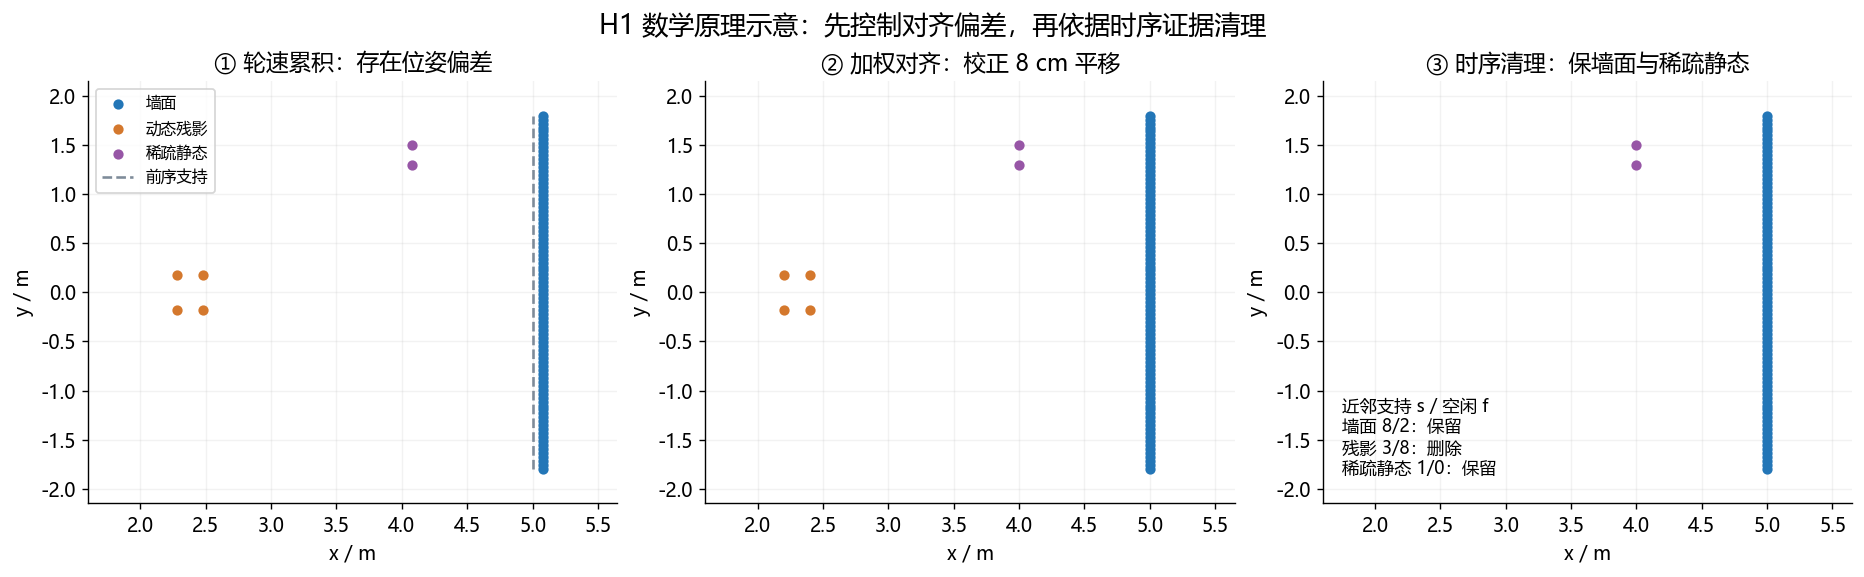

In [2]:
# 构造示意：用纯平移特例展示加权对齐，完整实现还估计旋转
wall = np.column_stack([np.full(90, 5.), np.linspace(-1.8, 1.8, 90)])
ghost = np.array([[2.2, -.18], [2.2, .18], [2.4, -.18], [2.4, .18]])
rare = np.array([[4., 1.3], [4., 1.5]])
offset = np.array([.08, 0.])
raw_wall = wall + offset
# 对应只取静态历史支持，动态点不参与本示意的位姿增量
residual = np.linalg.norm(raw_wall-wall, axis=1)
weights = np.minimum(1., .05/np.maximum(residual, 1e-9))
ids = np.argsort(residual)[:int(.7*len(residual))]
delta = ((wall[ids]-raw_wall[ids])*weights[ids,None]).sum(axis=0)/weights[ids].sum()
np.testing.assert_allclose(delta, -offset, atol=1e-12)
support = np.array([8, 3, 1])
free = np.array([2, 8, 0])
keep = (free < 3) | (free < 1.5*support)
assert keep.tolist() == [True, False, True]
groups, names, colors = [wall, ghost, rare], ['墙面', '动态残影', '稀疏静态'], [BLUE, ORANGE, PURPLE]
fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.5), layout='constrained')
for stage, ax in enumerate(axes):
    for points, name, color, retained in zip(groups,names,colors,keep):
        if stage == 2 and not retained: continue
        values = points+offset if stage == 0 else points+offset+delta
        ax.scatter(*values.T, color=color, s=24, label=name, zorder=3)
    ax.plot(wall[:,0],wall[:,1],'--',color=GREY,lw=1.5,label='前序支持')
    ax.set(xlim=(1.6,5.65),ylim=(-2.15,2.15),xlabel='x / m',ylabel='y / m',
           title=['① 轮速累积：存在位姿偏差','② 加权对齐：校正 8 cm 平移','③ 时序清理：保墙面与稀疏静态'][stage])
    tidy(ax)
axes[0].legend(loc='upper left',fontsize=9)
axes[2].text(1.75,-1.85,'近邻支持 s / 空闲 f\n墙面 8/2：保留\n残影 3/8：删除\n稀疏静态 1/0：保留',fontsize=10)
fig.suptitle('H1 数学原理示意：先控制对齐偏差，再依据时序证据清理',fontsize=15)
plt.show(); plt.close(fig)


**实际验证：同一原始A重建，另采动态B三次。**

**A · 清图比例**

| 方法 | DA ↑ | SA ↑ |
| --- | --- | --- |
| M₀ · Raw：轮速位姿累积 | 5.13% | 99.50% |
| M₁ · 自写对齐＋时序清理 | 58.97% | 99.67% |

**B · 冻结地图后定位：合并三轮共同有效样本。**

| 地图／相同AMCL | XY RMSE / cm ↓ |
| --- | --- |
| M₀ · Raw：轮速位姿累积 | 5.82 |
| M₁ · 自写对齐＋时序清理 | 4.65 |

本批次满足清图条件，且三次新B汇总定位误差下降；不能外推为所有场景的保证。

旧逐格过滤5.72→6.11 cm的负结果保留。开发消融区分只清理、只对齐与联合方法；最终B未用于调参。

[逐轮数值与录像](https://github.com/p20030920p/SLAM_Learning/blob/main/docs/HOME.zh-CN.md#own-dynamic-b)

<a id="h2"></a>
## H2｜统一点的采样参考时刻

**H2：统一点的采样参考时刻，再分别检验地图几何和定位。**

**12．核心公式三：运动畸变补偿。** $\mathbf z_i=(x_i,y_i,1)^{\mathsf T}$是在$t_i$采集的局部齐次点；$\hat T(t)\in\mathrm{SE}(2)$由轮速插值和传感器外参得到，从该时刻传感器系变换到固定地图系。$t_e$为扫描末时刻：

$$
\boxed{\boldsymbol{\bar{\mathbf z}_i=\hat T(t_e)^{-1}\hat T(t_i)\mathbf z_i}}
$$

从右向左理解：先用$\hat T(t_i)$将点放入固定坐标系，再用$\hat T(t_e)^{-1}$转入扫描末时刻坐标系。$M_0$把混合时刻的点直接当作$t_e$采集；$M_1$先补偿。两图都用$\hat T(t_e)$融合，其他步骤相同；H2不额外开启H1过滤。

**口头表述：**利用机器人运动估计，把不同时刻测到的点统一到同一参考时刻。它补偿机器人自身运动，不会自动补偿物体自身运动；也依赖轮速估计质量。

**13．地图几何误差。** 从本项A重新构造静态参照$S$，沿用最近距离$d$：

$$
E_{\rm map}(M)=\sqrt{\frac1{|M|}\sum_{\mathbf x\in M}d(\mathbf x,S)^2}.
$$

逐个计算地图点到静态参照的最近距离，再平方、平均和开平方。这是“地图到已观测静态支持”的单向距离，不能单独评价完整性；空图判为建图失败。

**14．H2的联合检验条件。**

$$
E_{\rm map}(M_1)<E_{\rm map}(M_0)\quad\land\quad E_{{\rm loc},1}<E_{{\rm loc},0}.
$$

几何评分下降后，还要验证独立定位误差下降；若只有前一项成立，只支持几何评分改善。H2当前是单轮探索，稳定收益仍需重复验证。

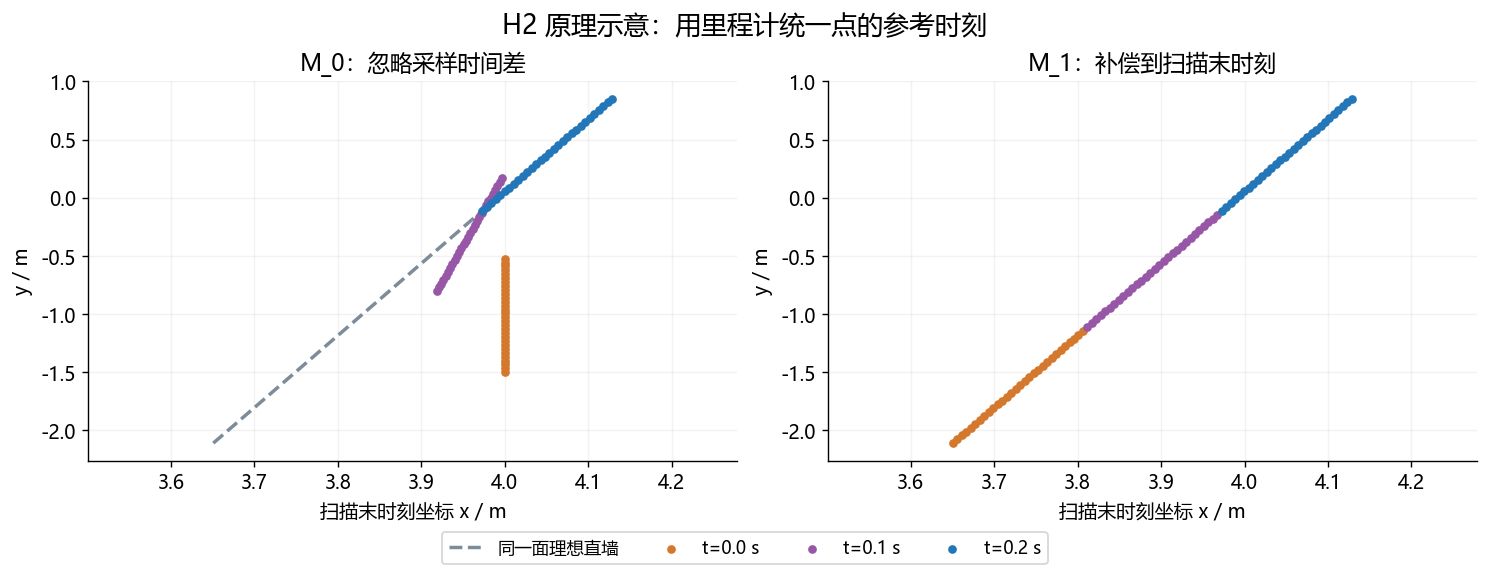

In [3]:
# 可改参数：扫描跨度、角速度、线速度
scan_span, yaw_speed, linear_speed = .2, .8, .3

def T_odom(t):
    angle = yaw_speed * t
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, linear_speed*t], [s, c, 0.], [0., 0., 1.]])

def apply_T(T, points):
    return points @ T[:2, :2].T + T[:2, 2]

wall_world = np.column_stack([np.full(90, 4.), np.linspace(-1.5, 1.5, 90)])
times = np.repeat([0., scan_span/2, scan_span], 30)
T_end = T_odom(scan_span)
raw, corrected = np.zeros_like(wall_world), np.zeros_like(wall_world)
for t in np.unique(times):
    mask = times == t
    T_i = T_odom(t)
    raw[mask] = apply_T(np.linalg.inv(T_i), wall_world[mask])
    corrected[mask] = apply_T(np.linalg.inv(T_end) @ T_i, raw[mask])  # 核心公式
reference = apply_T(np.linalg.inv(T_end), wall_world)
np.testing.assert_allclose(corrected, reference, atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), layout='constrained')
palette = [ORANGE, PURPLE, BLUE]
for ax, points, title in zip(axes, [raw, corrected], ['M_0：忽略采样时间差', 'M_1：补偿到扫描末时刻']):
    ax.plot(*reference.T, '--', color=GREY, lw=2, label='同一面理想直墙')
    for t, color in zip(np.unique(times), palette):
        mask = times == t
        ax.scatter(*points[mask].T, s=16, color=color, label=f't={t:.1f} s', zorder=3)
    all_points = np.vstack([raw, corrected, reference])
    lo, hi = all_points.min(axis=0)-.15, all_points.max(axis=0)+.15
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), xlabel='扫描末时刻坐标 x / m', ylabel='y / m', title=title)
    tidy(ax)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, fontsize=10)
fig.suptitle('H2 原理示意：用里程计统一点的参考时刻', fontsize=15)
plt.show(); plt.close(fig)

**实际实验：运动场景，单轮 A/B。**

**A · 地图几何：E_map 是地图到静态支持的单向距离 RMSE。**

| 方法 | 地图 RMSE / cm ↓ |
| --- | --- |
| M₀：补偿关 | 34.10 |
| M₁：补偿开 | 4.57 |

**B · 冻结地图后定位**

| 地图／相同 AMCL | 位置 RMSE / cm ↓ |
| --- | --- |
| M₀：补偿关 | 4.702 |
| M₁：补偿开 | 4.707 |

本轮只支持建图改善；定位误差未下降。里程计误差、地图结构与匹配条件仍会影响下游定位。

### 实验伪代码

```text
for test, scene in [(H1, static), (H1, dynamic), (H2, motion)]:
    A = acquire_scans_and_wheel_odometry(scene)
    if test == H1:
        M0 = integrate_A_with_wheel_poses(A)
        h, s, f = initialize_grid_evidence()
        M1 = empty_map()
        previous_wheel, previous_corrected = None, None
        for scan in A.in_time_order():
            wheel = sensor_pose_from_wheel_odometry(scan)
            predicted = wheel if previous_wheel is None else previous_corrected @ inverse(previous_wheel) @ wheel
            reference = previous_retained_cells_with_support(M1, s, min_bins=3)
            corrected = own_robust_SE2_alignment_or_wheel_fallback(scan, predicted, reference)
            points = transform_scan(scan, corrected)
            bin = floor(scan.time / 0.5)
            add_hits_once_per_cell_and_bin(h, points, bin)
            add_neighborhood_support_once_per_bin(s, points, bin, radius=0.10)
            add_free_crossings_once_per_bin(f, points, corrected, bin, stop_before_return=0.15)
            M1 = cell_centers_where((h > 0) & ((f < 3) | (f < 1.5 * s)))
            previous_wheel, previous_corrected = wheel, corrected
    else:
        M0 = integrate_A(A, point_compensation=False)
        M1 = integrate_A(A, point_compensation=True)  # no H1 filtering
    freeze(M0, M1)
    B = acquire_independent_scans_and_wheel_odometry(scene)
    positions = {}
    for m, map in [(0, M0), (1, M1)]:
        positions[m] = same_AMCL(B.scans, B.odometry, grid_of(map), same_initial_config)
    # Truth enters only here; references are shared across controls
    S, D = scoring_references_from_A_truth(A)
    if test == H1:
        score_SA(M0, M1, S)
        if scene == dynamic: score_DA(M0, M1, D)
    if test == H2: score_map_RMSE(M0, M1, S)
    score_position_RMSE(positions, B_truth, common_valid_times)
```